# PROYECTO INTEGRADOR
## Análisis de casos de dengue en Antioquia (2025)

**Asignatura:** Programación y Ciencia de Datos

**Grupo:** 1 — Salud pública

**Integrantes:**
- Sebastian Rincon Rodriguez
- Maria Camila Vallejos Basante

**Dataset:** `salud_dengue_antioquia_2025.csv`

**Objetivo:** Analizar la distribución temporal, territorial y clínica de los casos de dengue para identificar patrones que permitan orientar decisiones de prevención, vigilancia epidemiológica y atención en salud pública.

**Ejecución:** Ejecutar las celdas en orden, desde el inicio hasta las conclusiones. El notebook busca el CSV en las ubicaciones habituales del proyecto y, si no lo encuentra en Google Colab, permite cargarlo manualmente.

**Visualizaciones:** Las cinco gráficas se guardan automáticamente en la carpeta `visualizaciones/`.

**Nota:** Los datos utilizados son sintéticos y fueron generados con fines académicos. Las conclusiones corresponden exclusivamente al conjunto de datos y no representan cifras epidemiológicas reales de Antioquia. Las asociaciones estadísticas no demuestran causalidad y los conteos no equivalen a tasas de incidencia.

In [67]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Librerías cargadas correctamente")

Librerías cargadas correctamente


In [68]:
df = pd.read_csv("salud_dengue_antioquia_2025.csv")

print("Dimensiones del conjunto de datos:")
print(df.shape)

print("\nPrimeras cinco filas:")
display(df.head())

Dimensiones del conjunto de datos:
(2859, 18)

Primeras cinco filas:


,id_caso,fecha_notificacion,semana_epidemiologica,municipio,subregion,zona,sexo,edad,regimen_salud,ocupacion,dias_sintomas_a_consulta,clasificacion,plaquetas_miles,hospitalizado,dias_hospitalizacion,condicion_final,temperatura_media_semana,precipitacion_semana_mm
0,DEN-00001,2024-12-29,1,Turbo,Urabá,Rural,M,56.0,Subsidiado,NaN,4.0,Dengue sin signos de alarma,146.0,No,NaN,Vivo,27.9,45.5
1,DEN-00002,2024-12-29,1,Turbo,Urabá,Urbana,F,46.0,Subsidiado,NaN,1.0,Dengue sin signos de alarma,183.0,No,NaN,Vivo,27.9,45.5
2,DEN-00003,2024-12-29,1,Apartadó,Urabá,Urbana,M,7.0,Contributivo,NaN,2.0,Dengue sin signos de alarma,81.0,No,NaN,Vivo,26.8,45.8
3,DEN-00004,2024-12-30,1,Turbo,Urabá,Urbana,F,36.0,Subsidiado,NaN,2.0,Dengue sin signos de alarma,NaN,No,NaN,Vivo,27.9,45.5
4,DEN-00005,2024-12-30,1,Caucasia,Bajo Cauca,Rural,F,5.0,No asegurado,Empleado,5.0,Dengue sin signos de alarma,121.0,No,NaN,Vivo,27.4,40.7


In [69]:
print("INFORMACIÓN GENERAL")
print(df.info())

print("\nTIPOS DE VARIABLES")
display(df.dtypes)

print("\nESTADÍSTICAS DESCRIPTIVAS")
display(df.describe(include="all").T)

print("\nVALORES FALTANTES")
display(df.isnull().sum())

print("\nPORCENTAJE DE FALTANTES")
display((df.isnull().mean() * 100).round(2))

print("\nFILAS DUPLICADAS")
print(df.duplicated().sum())

INFORMACIÓN GENERAL
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2859 entries, 0 to 2858
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id_caso                   2859 non-null   object 
 1   fecha_notificacion        2859 non-null   object 
 2   semana_epidemiologica     2859 non-null   int64  
 3   municipio                 2859 non-null   object 
 4   subregion                 2859 non-null   object 
 5   zona                      2859 non-null   object 
 6   sexo                      2859 non-null   object 
 7   edad                      2761 non-null   float64
 8   regimen_salud             2676 non-null   object 
 9   ocupacion                 913 non-null    object 
 10  dias_sintomas_a_consulta  2703 non-null   float64
 11  clasificacion             2859 non-null   object 
 12  plaquetas_miles           2439 non-null   float64
 13  hospitalizado             2859 non-null   o

,0
id_caso,object
fecha_notificacion,object
semana_epidemiologica,int64
municipio,object
subregion,object
zona,object
sexo,object
edad,float64
regimen_salud,object
ocupacion,object



ESTADÍSTICAS DESCRIPTIVAS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id_caso,2859,2859,DEN-00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fecha_notificacion,2859,362,2025-05-20,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
semana_epidemiologica,2859.0,NaN,NaN,NaN,27.365862,14.128364,1.0,17.0,25.0,41.0,52.0
municipio,2859,10,Medellín,595,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subregion,2859,6,Urabá,998,NaN,NaN,NaN,NaN,NaN,NaN,NaN
zona,2859,2,Urbana,2056,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sexo,2859,2,F,1451,NaN,NaN,NaN,NaN,NaN,NaN,NaN
edad,2761.0,NaN,NaN,NaN,34.448388,23.645594,0.0,12.0,35.0,50.0,135.0
regimen_salud,2676,4,Subsidiado,1365,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ocupacion,913,8,Empleado,176,NaN,NaN,NaN,NaN,NaN,NaN,NaN



VALORES FALTANTES


,0
id_caso,0
fecha_notificacion,0
semana_epidemiologica,0
municipio,0
subregion,0
zona,0
sexo,0
edad,98
regimen_salud,183
ocupacion,1946



PORCENTAJE DE FALTANTES


,0
id_caso,0.00
fecha_notificacion,0.00
semana_epidemiologica,0.00
municipio,0.00
subregion,0.00
zona,0.00
sexo,0.00
edad,3.43
regimen_salud,6.40
ocupacion,68.07



FILAS DUPLICADAS
0


## Diagnóstico de calidad de los datos

En esta sección se identifican los problemas de calidad presentes en el conjunto de datos, incluyendo valores faltantes, registros duplicados, valores atípicos, datos imposibles e inconsistencias en las variables categóricas.

El objetivo es determinar qué información necesita limpieza y qué valores deben conservarse, teniendo en cuenta el diccionario de datos.

In [70]:
print("Filas duplicadas:")
print(df.duplicated().sum())

print("\nIdentificadores duplicados:")
print(df["id_caso"].duplicated().sum())

print("\nCantidad total de registros:")
print(len(df))


Filas duplicadas:
0

Identificadores duplicados:
0

Cantidad total de registros:
2859


In [71]:
faltantes = pd.DataFrame({
    "Cantidad de faltantes": df.isnull().sum(),
    "Porcentaje (%)": (df.isnull().mean() * 100).round(2)
})

faltantes = faltantes.sort_values(
    by="Porcentaje (%)",
    ascending=False
)

display(faltantes)


,Cantidad de faltantes,Porcentaje (%)
dias_hospitalizacion,2260,79.05
ocupacion,1946,68.07
plaquetas_miles,420,14.69
regimen_salud,183,6.40
dias_sintomas_a_consulta,156,5.46
precipitacion_semana_mm,108,3.78
edad,98,3.43
id_caso,0,0.00
fecha_notificacion,0,0.00
semana_epidemiologica,0,0.00


### Interpretación de los valores faltantes

El análisis evidencia que las variables con mayor cantidad de datos faltantes son `dias_hospitalizacion`, con 2.260 registros (79,05 %), y `ocupacion`, con 1.946 registros (68,07 %).

Los valores faltantes de `dias_hospitalizacion` corresponden principalmente a pacientes que no fueron hospitalizados. Por esta razón, no deben imputarse, ya que representan una situación en la que el dato no aplica.

La variable `ocupacion` presenta un porcentaje muy elevado de información faltante, por lo que se considera conveniente excluirla del análisis principal.

Por otro lado, las variables `plaquetas_miles`, `regimen_salud`, `dias_sintomas_a_consulta`, `precipitacion_semana_mm` y `edad` también presentan valores faltantes. Algunas de ellas son importantes para responder las preguntas del proyecto, por lo que se evaluarán estrategias de imputación apropiadas.

Las demás variables no presentan valores faltantes, lo que facilita su utilización en el análisis.

In [72]:
print("Edades menores de cero:")
display(df[df["edad"] < 0])

print("Edades mayores de 110:")
display(df[df["edad"] > 110])

print("Demoras mayores a 30 días:")
display(
    df[df["dias_sintomas_a_consulta"] > 30][
        ["id_caso", "dias_sintomas_a_consulta", "clasificacion"]
    ]
)

print("Plaquetas negativas:")
display(df[df["plaquetas_miles"] < 0])

print("Plaquetas superiores a 1000:")
display(df[df["plaquetas_miles"] > 1000])


Edades menores de cero:


,id_caso,fecha_notificacion,semana_epidemiologica,municipio,subregion,zona,sexo,edad,regimen_salud,ocupacion,dias_sintomas_a_consulta,clasificacion,plaquetas_miles,hospitalizado,dias_hospitalizacion,condicion_final,temperatura_media_semana,precipitacion_semana_mm


Edades mayores de 110:


,id_caso,fecha_notificacion,semana_epidemiologica,municipio,subregion,zona,sexo,edad,regimen_salud,ocupacion,dias_sintomas_a_consulta,clasificacion,plaquetas_miles,hospitalizado,dias_hospitalizacion,condicion_final,temperatura_media_semana,precipitacion_semana_mm
83,DEN-00084,2025-01-16,3,Itagüí,Valle de Aburrá,Urbana,F,135.0,Contributivo,NaN,4.0,Dengue sin signos de alarma,109.0,No,NaN,Vivo,22.6,63.7
1478,DEN-01479,2025-06-21,25,Turbo,Urabá,Urbana,M,120.0,Contributivo,Empleado,2.0,Dengue sin signos de alarma,104.0,No,NaN,Vivo,28.4,32.1
2725,DEN-02726,2025-12-09,50,Caucasia,Bajo Cauca,Urbana,F,135.0,Subsidiado,NaN,4.0,Dengue grave,55.0,Sí,7.0,Vivo,27.8,34.2


Demoras mayores a 30 días:


,id_caso,dias_sintomas_a_consulta,clasificacion
802,DEN-00803,45.0,Dengue sin signos de alarma
1417,DEN-01418,60.0,Dengue sin signos de alarma
2090,DEN-02091,45.0,Dengue sin signos de alarma


Plaquetas negativas:


,id_caso,fecha_notificacion,semana_epidemiologica,municipio,subregion,zona,sexo,edad,regimen_salud,ocupacion,dias_sintomas_a_consulta,clasificacion,plaquetas_miles,hospitalizado,dias_hospitalizacion,condicion_final,temperatura_media_semana,precipitacion_semana_mm


Plaquetas superiores a 1000:


,id_caso,fecha_notificacion,semana_epidemiologica,municipio,subregion,zona,sexo,edad,regimen_salud,ocupacion,dias_sintomas_a_consulta,clasificacion,plaquetas_miles,hospitalizado,dias_hospitalizacion,condicion_final,temperatura_media_semana,precipitacion_semana_mm


In [73]:

columnas_categoricas = [
    "municipio",
    "subregion",
    "zona",
    "sexo",
    "regimen_salud",
    "clasificacion",
    "hospitalizado",
    "condicion_final"
]

for columna in columnas_categoricas:
    print("\nVariable:", columna)
    display(df[columna].value_counts(dropna=False))



Variable: municipio


,count
municipio,
Medellín,595
Apartadó,542
Caucasia,461
Turbo,456
Puerto Berrío,319
Bello,187
Santa Fe de Antioquia,170
Itagüí,74
Envigado,52



Variable: subregion


,count
subregion,
Urabá,998
Valle de Aburrá,908
Bajo Cauca,461
Magdalena Medio,319
Occidente,170
Oriente,3



Variable: zona


,count
zona,
Urbana,2056
Rural,803


... (6 outputs left out)


Variable: hospitalizado


,count
hospitalizado,
No,2260
Sí,599



Variable: condicion_final


,count
condicion_final,
Vivo,2851
Fallecido,8


In [74]:
tabla_hospitalizacion = pd.crosstab(
    df["hospitalizado"],
    df["dias_hospitalizacion"].isnull(),
    margins=True
)

display(tabla_hospitalizacion)


dias_hospitalizacion,False,True,All
hospitalizado,,,
No,0,2260,2260
Sí,599,0,599
All,599,2260,2859


### Interpretación de las variables categóricas

El conjunto de datos contiene 2.859 casos de dengue registrados en diez municipios de Antioquia.

Medellín presenta la mayor cantidad de casos, con 595, seguido de Apartadó con 542, Caucasia con 461 y Turbo con 456. Por subregiones, Urabá registra 998 casos y el Valle de Aburrá 908.

La mayoría de los registros corresponden a zonas urbanas, con 2.056 casos, mientras que 803 corresponden a zonas rurales. La distribución por sexo es relativamente equilibrada: 1.451 mujeres y 1.408 hombres.

En cuanto al régimen de salud, predomina el subsidiado, con 1.365 registros, seguido del contributivo, con 1.075. Se identifican 183 registros sin información sobre esta variable.

Respecto a la clasificación del dengue, 2.346 casos no presentan signos de alarma, 416 presentan signos de alarma y 97 corresponden a dengue grave.

Finalmente, 599 pacientes fueron hospitalizados y se registraron 8 fallecimientos. Estos resultados muestran la importancia de analizar la gravedad de los casos y su distribución territorial para orientar las decisiones de salud pública.

### Interpretación del diagnóstico de calidad

El análisis permitió identificar diferentes problemas de calidad en el conjunto de datos.

La variable `ocupacion` presenta una cantidad elevada de valores faltantes, por lo que se evaluará su eliminación del análisis.

La variable `dias_hospitalizacion` presenta un porcentaje elevado de faltantes; sin embargo, según el diccionario de datos, estos corresponden a pacientes que no fueron hospitalizados. Por esta razón, se consideran faltantes estructurales y no deben imputarse.

También se deben revisar las edades superiores a 110 años, ya que pueden representar registros sospechosos. Los valores extremos de plaquetas y los tiempos prolongados entre síntomas y consulta se analizarán con criterio clínico y estadístico antes de tomar decisiones.

Finalmente, se revisaron los registros duplicados y las categorías de las variables cualitativas para identificar posibles inconsistencias.

In [75]:
print("EDADES MAYORES DE 110 AÑOS")
display(df[df["edad"] > 110][
    ["id_caso", "edad", "sexo", "municipio"]
])

print("\nDEMORAS MAYORES DE 30 DÍAS")
display(df[df["dias_sintomas_a_consulta"] > 30][
    ["id_caso", "dias_sintomas_a_consulta", "clasificacion"]
])

print("\nPLAQUETAS NEGATIVAS")
display(df[df["plaquetas_miles"] < 0])

print("\nPLAQUETAS SUPERIORES A 1000")
display(df[df["plaquetas_miles"] > 1000])

EDADES MAYORES DE 110 AÑOS


,id_caso,edad,sexo,municipio
83,DEN-00084,135.0,F,Itagüí
1478,DEN-01479,120.0,M,Turbo
2725,DEN-02726,135.0,F,Caucasia



DEMORAS MAYORES DE 30 DÍAS


,id_caso,dias_sintomas_a_consulta,clasificacion
802,DEN-00803,45.0,Dengue sin signos de alarma
1417,DEN-01418,60.0,Dengue sin signos de alarma
2090,DEN-02091,45.0,Dengue sin signos de alarma



PLAQUETAS NEGATIVAS


,id_caso,fecha_notificacion,semana_epidemiologica,municipio,subregion,zona,sexo,edad,regimen_salud,ocupacion,dias_sintomas_a_consulta,clasificacion,plaquetas_miles,hospitalizado,dias_hospitalizacion,condicion_final,temperatura_media_semana,precipitacion_semana_mm



PLAQUETAS SUPERIORES A 1000


,id_caso,fecha_notificacion,semana_epidemiologica,municipio,subregion,zona,sexo,edad,regimen_salud,ocupacion,dias_sintomas_a_consulta,clasificacion,plaquetas_miles,hospitalizado,dias_hospitalizacion,condicion_final,temperatura_media_semana,precipitacion_semana_mm


### Interpretación de valores sospechosos

Durante la revisión de calidad se identificaron tres registros con edades superiores a 110 años: 120, 135 y 135 años. Estos valores se consideran sospechosos porque se encuentran fuera de un rango razonable para el análisis de la población.

También se encontraron tres registros con demoras superiores a 30 días entre el inicio de los síntomas y la consulta médica: 45, 60 y 45 días. Sin embargo, estos valores se conservarán porque podrían representar situaciones reales de consulta tardía.

No se encontraron valores negativos en el recuento de plaquetas ni valores superiores a 1.000 miles/µL.

Como decisión de limpieza, las tres edades sospechosas se convertirán en valores faltantes y posteriormente serán imputadas mediante una estrategia estadística. No se eliminarán las filas completas, con el propósito de conservar la información restante de cada caso.

In [76]:
df_limpio = df.copy()

filas_antes = len(df_limpio)

df_limpio["fecha_notificacion"] = pd.to_datetime(
    df_limpio["fecha_notificacion"],
    errors="coerce"
)

print("Filas originales:", filas_antes)
print("Filas en la copia:", len(df_limpio))
print("Fechas que no pudieron convertirse:",
      df_limpio["fecha_notificacion"].isna().sum())

display(df_limpio.head())

Filas originales: 2859
Filas en la copia: 2859
Fechas que no pudieron convertirse: 0


,id_caso,fecha_notificacion,semana_epidemiologica,municipio,subregion,zona,sexo,edad,regimen_salud,ocupacion,dias_sintomas_a_consulta,clasificacion,plaquetas_miles,hospitalizado,dias_hospitalizacion,condicion_final,temperatura_media_semana,precipitacion_semana_mm
0,DEN-00001,2024-12-29,1,Turbo,Urabá,Rural,M,56.0,Subsidiado,NaN,4.0,Dengue sin signos de alarma,146.0,No,NaN,Vivo,27.9,45.5
1,DEN-00002,2024-12-29,1,Turbo,Urabá,Urbana,F,46.0,Subsidiado,NaN,1.0,Dengue sin signos de alarma,183.0,No,NaN,Vivo,27.9,45.5
2,DEN-00003,2024-12-29,1,Apartadó,Urabá,Urbana,M,7.0,Contributivo,NaN,2.0,Dengue sin signos de alarma,81.0,No,NaN,Vivo,26.8,45.8
3,DEN-00004,2024-12-30,1,Turbo,Urabá,Urbana,F,36.0,Subsidiado,NaN,2.0,Dengue sin signos de alarma,NaN,No,NaN,Vivo,27.9,45.5
4,DEN-00005,2024-12-30,1,Caucasia,Bajo Cauca,Rural,F,5.0,No asegurado,Empleado,5.0,Dengue sin signos de alarma,121.0,No,NaN,Vivo,27.4,40.7


In [77]:
edades_sospechosas = (
    (df_limpio["edad"] < 0) |
    (df_limpio["edad"] > 110)
)

print("Edades sospechosas:", edades_sospechosas.sum())

df_limpio.loc[edades_sospechosas, "edad"] = np.nan

edad_imputar = df_limpio["edad"].isna().sum()

df_limpio["edad"] = df_limpio["edad"].fillna(
    df_limpio.groupby("sexo")["edad"].transform("median")
)

df_limpio["edad"] = df_limpio["edad"].fillna(
    df_limpio["edad"].median()
)

print("Edades imputadas:", edad_imputar)
print("Edades faltantes restantes:",
      df_limpio["edad"].isna().sum())

Edades sospechosas: 3
Edades imputadas: 101
Edades faltantes restantes: 0


In [78]:
plaquetas_imputar = df_limpio["plaquetas_miles"].isna().sum()

df_limpio["plaquetas_miles"] = df_limpio["plaquetas_miles"].fillna(
    df_limpio.groupby("clasificacion")["plaquetas_miles"].transform("median")
)

df_limpio["plaquetas_miles"] = df_limpio["plaquetas_miles"].fillna(
    df_limpio["plaquetas_miles"].median()
)

print("Plaquetas imputadas:", plaquetas_imputar)
print("Faltantes restantes:",
      df_limpio["plaquetas_miles"].isna().sum())

Plaquetas imputadas: 420
Faltantes restantes: 0


In [79]:
lluvia_imputar = df_limpio["precipitacion_semana_mm"].isna().sum()

df_limpio["precipitacion_semana_mm"] = (
    df_limpio["precipitacion_semana_mm"].fillna(
        df_limpio.groupby("municipio")[
            "precipitacion_semana_mm"
        ].transform("median")
    )
)

df_limpio["precipitacion_semana_mm"] = (
    df_limpio["precipitacion_semana_mm"].fillna(
        df_limpio["precipitacion_semana_mm"].median()
    )
)

print("Valores de precipitación imputados:", lluvia_imputar)
print("Faltantes restantes:",
      df_limpio["precipitacion_semana_mm"].isna().sum())

Valores de precipitación imputados: 108
Faltantes restantes: 0


In [80]:
df_limpio = df_limpio.drop(columns=["ocupacion"])

print("¿Se eliminó ocupacion?",
      "ocupacion" not in df_limpio.columns)

print("Filas después de la eliminación:", len(df_limpio))
print("Columnas restantes:", len(df_limpio.columns))

¿Se eliminó ocupacion? True
Filas después de la eliminación: 2859
Columnas restantes: 17


In [81]:
print("RESUMEN DE LA LIMPIEZA")

print("Filas antes:", filas_antes)
print("Filas después:", len(df_limpio))
print("Filas eliminadas:", filas_antes - len(df_limpio))

print("\nVALORES FALTANTES DESPUÉS DE LA LIMPIEZA")
display(
    pd.DataFrame({
        "Faltantes": df_limpio.isna().sum(),
        "Porcentaje (%)": (
            df_limpio.isna().mean() * 100
        ).round(2)
    }).sort_values("Faltantes", ascending=False)
)

print("\nDIMENSIONES FINALES")
print(df_limpio.shape)

print("\nTIPOS DE DATOS")
display(df_limpio.dtypes)

RESUMEN DE LA LIMPIEZA
Filas antes: 2859
Filas después: 2859
Filas eliminadas: 0

VALORES FALTANTES DESPUÉS DE LA LIMPIEZA


,Faltantes,Porcentaje (%)
dias_hospitalizacion,2260,79.05
regimen_salud,183,6.40
dias_sintomas_a_consulta,156,5.46
id_caso,0,0.00
fecha_notificacion,0,0.00
subregion,0,0.00
zona,0,0.00
municipio,0,0.00
semana_epidemiologica,0,0.00
edad,0,0.00



DIMENSIONES FINALES
(2859, 17)

TIPOS DE DATOS


,0
id_caso,object
fecha_notificacion,datetime64[ns]
semana_epidemiologica,int64
municipio,object
subregion,object
zona,object
sexo,object
edad,float64
regimen_salud,object
dias_sintomas_a_consulta,float64


### Costo de las decisiones de limpieza

In [82]:
costo_limpieza = pd.DataFrame({
    "Decisión": [
        "Conversión de fecha",
        "Tratamiento de edades sospechosas y faltantes",
        "Imputación de plaquetas",
        "Imputación de precipitación",
        "Eliminación de ocupacion",
        "Conservar faltantes de dias_hospitalizacion",
        "Conservar faltantes de regimen_salud",
        "Conservar faltantes de dias_sintomas_a_consulta"
    ],
    "Cantidad de valores afectados": [
        0,
        edad_imputar,
        plaquetas_imputar,
        lluvia_imputar,
        1946,
        2260,
        183,
        156
    ],
    "Filas eliminadas": [
        0, 0, 0, 0, 0, 0, 0, 0
    ]
})

display(costo_limpieza)

,Decisión,Cantidad de valores afectados,Filas eliminadas
0,Conversión de fecha,0,0
1,Tratamiento de edades sospechosas y faltantes,101,0
2,Imputación de plaquetas,420,0
3,Imputación de precipitación,108,0
4,Eliminación de ocupacion,1946,0
5,Conservar faltantes de dias_hospitalizacion,2260,0
6,Conservar faltantes de regimen_salud,183,0
7,Conservar faltantes de dias_sintomas_a_consulta,156,0


### Conclusión del proceso de limpieza

Después de aplicar las estrategias de limpieza, el conjunto de datos pasó de 18 a 17 columnas y conservó sus 2.859 registros originales.

Se convirtió la variable `fecha_notificacion` al formato datetime. Se identificaron tres edades sospechosas, que junto con los valores faltantes originales fueron tratadas mediante imputación por la mediana según el sexo. Los valores faltantes de `plaquetas_miles` se imputaron utilizando la mediana según la clasificación del dengue, mientras que los faltantes de precipitación se completaron mediante la mediana por municipio.

Se eliminó la variable `ocupacion` debido a que presentaba un 68,07 % de información faltante. Se conservaron los valores vacíos de `dias_hospitalizacion`, porque no aplican a los pacientes que no fueron hospitalizados.

Finalmente, no se eliminaron filas y se conservaron algunos valores faltantes de régimen de salud y días de síntomas a consulta, los cuales serán considerados como limitaciones en los análisis correspondientes.

### Pregunta 1. Comportamiento semanal de los casos de dengue y su relación con la precipitación

In [83]:
casos_semana = (
    df_limpio.groupby("semana_epidemiologica")
    .agg(
        total_casos=("id_caso", "count"),
        precipitacion_promedio=("precipitacion_semana_mm", "mean"),
        temperatura_promedio=("temperatura_media_semana", "mean")
    )
    .reset_index()
)

casos_semana = casos_semana.sort_values(
    "semana_epidemiologica"
)

display(casos_semana.head(10))

semanas_mayores = casos_semana.sort_values(
    "total_casos",
    ascending=False
)

print("LAS 10 SEMANAS CON MÁS CASOS")
display(semanas_mayores.head(10))

,semana_epidemiologica,total_casos,precipitacion_promedio,temperatura_promedio
0,1,26,40.119231,26.676923
1,2,35,47.082857,25.774286
2,3,35,41.174286,26.485714
3,4,35,43.437143,25.940000
4,5,29,44.296552,26.213793
5,6,39,47.079487,26.502564
6,7,38,38.018421,25.860526
7,8,33,38.212121,25.672727
8,9,38,41.955263,26.302632
9,10,59,53.037288,27.172881


LAS 10 SEMANAS CON MÁS CASOS


,semana_epidemiologica,total_casos,precipitacion_promedio,temperatura_promedio
20,21,119,59.060504,28.057983
21,22,101,59.236634,26.874257
19,20,98,65.057143,27.320408
22,23,93,34.716129,27.846237
16,17,91,83.415385,27.125275
17,18,84,78.863095,27.278571
18,19,80,83.273750,26.925000
47,48,79,55.702532,25.583544
42,43,76,87.765789,25.986842
23,24,75,40.806667,27.650667


In [84]:
casos_semana = casos_semana.sort_values(
    "semana_epidemiologica"
).copy()

casos_semana["lluvia_semana_anterior"] = (
    casos_semana["precipitacion_promedio"].shift(1)
)

correlacion_misma_semana = casos_semana[
    ["total_casos", "precipitacion_promedio"]
].corr().iloc[0, 1]

correlacion_semana_anterior = casos_semana[
    ["total_casos", "lluvia_semana_anterior"]
].corr().iloc[0, 1]

print("Correlación entre lluvia y casos de la misma semana:")
print(round(correlacion_misma_semana, 3))

print("\nCorrelación entre lluvia de la semana anterior y casos actuales:")
print(round(correlacion_semana_anterior, 3))

Correlación entre lluvia y casos de la misma semana:
0.361

Correlación entre lluvia de la semana anterior y casos actuales:
0.451


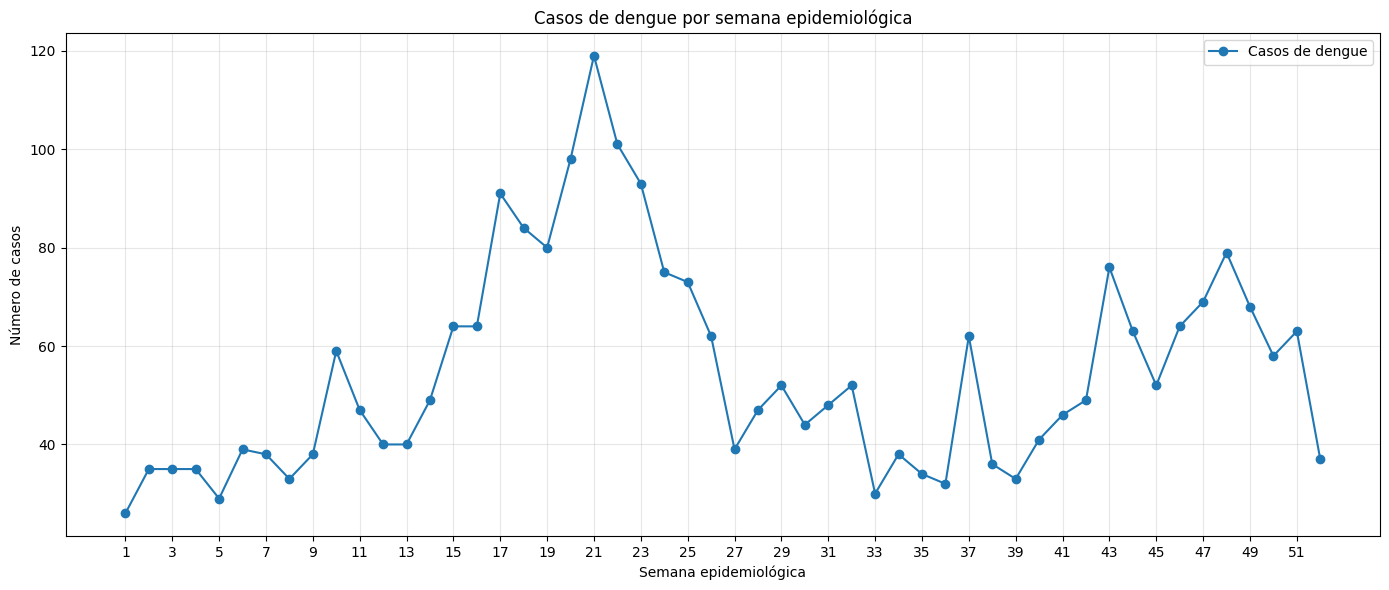

In [85]:
plt.figure(figsize=(14, 6))

plt.plot(
    casos_semana["semana_epidemiologica"],
    casos_semana["total_casos"],
    marker="o",
    label="Casos de dengue"
)

plt.title("Casos de dengue por semana epidemiológica")
plt.xlabel("Semana epidemiológica")
plt.ylabel("Número de casos")
plt.xticks(range(1, 53, 2))
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()

plt.savefig(
    DIR_VISUALIZACIONES / 'Casos de dengue por semana epidemiológica.png',
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Análisis preliminar de los casos semanales

El análisis de los casos de dengue por semana epidemiológica permitió identificar que la semana 21 presentó la mayor cantidad de notificaciones, con 119 casos. También se observaron cantidades elevadas durante las semanas 20, 22 y 23, lo que evidencia un periodo de incremento de casos alrededor de esas semanas.

La semana 17 registró 91 casos y una precipitación promedio de 83,42 mm. Por otra parte, la semana 43 presentó una precipitación promedio de 87,77 mm y 76 casos.

Estos resultados muestran que la precipitación puede ser una variable relevante para estudiar el comportamiento del dengue; sin embargo, todavía es necesario calcular la correlación entre las lluvias y los casos, considerando tanto la misma semana como la semana anterior.

Por lo tanto, no se puede afirmar todavía que exista una relación directa o causal entre la precipitación y el aumento de casos.

### Conclusión de la pregunta 1: comportamiento semanal y precipitación

El análisis de los 2.859 registros permitió identificar variaciones importantes en la cantidad de casos de dengue durante las semanas epidemiológicas de 2025.

La semana 21 presentó el mayor número de notificaciones, con 119 casos. También se observaron incrementos significativos entre las semanas 17 y 24, lo que evidencia un periodo de mayor concentración de casos.

Al analizar la relación entre la precipitación y los casos, se obtuvo una correlación de Pearson de 0,361 para la misma semana y de 0,451 al comparar la precipitación de la semana anterior con los casos actuales.

Estos resultados indican una asociación positiva moderada entre la precipitación previa y los casos de dengue. Esto sugiere que las condiciones de lluvia podrían estar relacionadas con el comportamiento posterior de la enfermedad.

Desde la perspectiva de salud pública, se recomienda prestar especial atención a los periodos de incremento de las lluvias y fortalecer las acciones preventivas y de control del mosquito transmisor. Sin embargo, los resultados representan asociaciones estadísticas y no demuestran causalidad.

### Pregunta 2. Distribución de casos por municipio y subregión

In [86]:
casos_municipio = (
    df_limpio.groupby("municipio")
    .agg(
        total_casos=("id_caso", "count"),
        cantidad_temperaturas=("temperatura_media_semana", "count"),
        temperatura_promedio=("temperatura_media_semana", "mean"),
        cantidad_precipitaciones=("precipitacion_semana_mm", "count"),
        precipitacion_promedio=("precipitacion_semana_mm", "mean")
    )
    .reset_index()
)

casos_municipio = casos_municipio.sort_values(
    by="total_casos",
    ascending=False
)

display(casos_municipio)

,municipio,total_casos,cantidad_temperaturas,temperatura_promedio,cantidad_precipitaciones,precipitacion_promedio
5,Medellín,595,595,23.806723,595,62.128067
0,Apartadó,542,542,27.953321,542,57.588376
2,Caucasia,461,461,28.644685,461,56.725597
9,Turbo,456,456,28.107018,456,58.064912
6,Puerto Berrío,319,319,28.604702,319,58.536050
1,Bello,187,187,23.243316,187,66.022460
8,Santa Fe de Antioquia,170,170,27.079412,170,59.647059
4,Itagüí,74,74,23.213514,74,60.260811
3,Envigado,52,52,22.607692,52,57.653846
7,Rionegro,3,3,19.233333,3,51.266667


In [87]:
casos_subregion = (
    df_limpio.groupby("subregion")
    .agg(
        total_casos=("id_caso", "count"),
        temperatura_promedio=("temperatura_media_semana", "mean"),
        precipitacion_promedio=("precipitacion_semana_mm", "mean")
    )
    .reset_index()
)
casos_subregion = casos_subregion.sort_values(
    by="total_casos",
    ascending=False
)

display(casos_subregion)

,subregion,total_casos,temperatura_promedio,precipitacion_promedio
4,Urabá,998,28.023547,57.806112
5,Valle de Aburrá,908,23.573678,62.521696
0,Bajo Cauca,461,28.644685,56.725597
1,Magdalena Medio,319,28.604702,58.536050
2,Occidente,170,27.079412,59.647059
3,Oriente,3,19.233333,51.266667


In [88]:
municipios_prioritarios = casos_municipio.loc[
    casos_municipio["total_casos"] > 300,
    [
        "municipio",
        "total_casos",
        "temperatura_promedio"
    ]
]

municipios_prioritarios = municipios_prioritarios.sort_values(
    "total_casos",
    ascending=False
)

display(municipios_prioritarios)

,municipio,total_casos,temperatura_promedio
5,Medellín,595,23.806723
0,Apartadó,542,27.953321
2,Caucasia,461,28.644685
9,Turbo,456,28.107018
6,Puerto Berrío,319,28.604702


In [89]:
municipios_temperatura = casos_municipio.sort_values(
    by="temperatura_promedio",
    ascending=False
)

display(municipios_temperatura)

,municipio,total_casos,cantidad_temperaturas,temperatura_promedio,cantidad_precipitaciones,precipitacion_promedio
2,Caucasia,461,461,28.644685,461,56.725597
6,Puerto Berrío,319,319,28.604702,319,58.536050
9,Turbo,456,456,28.107018,456,58.064912
0,Apartadó,542,542,27.953321,542,57.588376
8,Santa Fe de Antioquia,170,170,27.079412,170,59.647059
5,Medellín,595,595,23.806723,595,62.128067
1,Bello,187,187,23.243316,187,66.022460
4,Itagüí,74,74,23.213514,74,60.260811
3,Envigado,52,52,22.607692,52,57.653846
7,Rionegro,3,3,19.233333,3,51.266667


In [90]:
correlacion_temperatura = casos_municipio[
    ["total_casos", "temperatura_promedio"]
].corr().iloc[0, 1]

print(
    "Correlación entre temperatura y casos:",
    round(correlacion_temperatura, 3)
)

Correlación entre temperatura y casos: 0.657


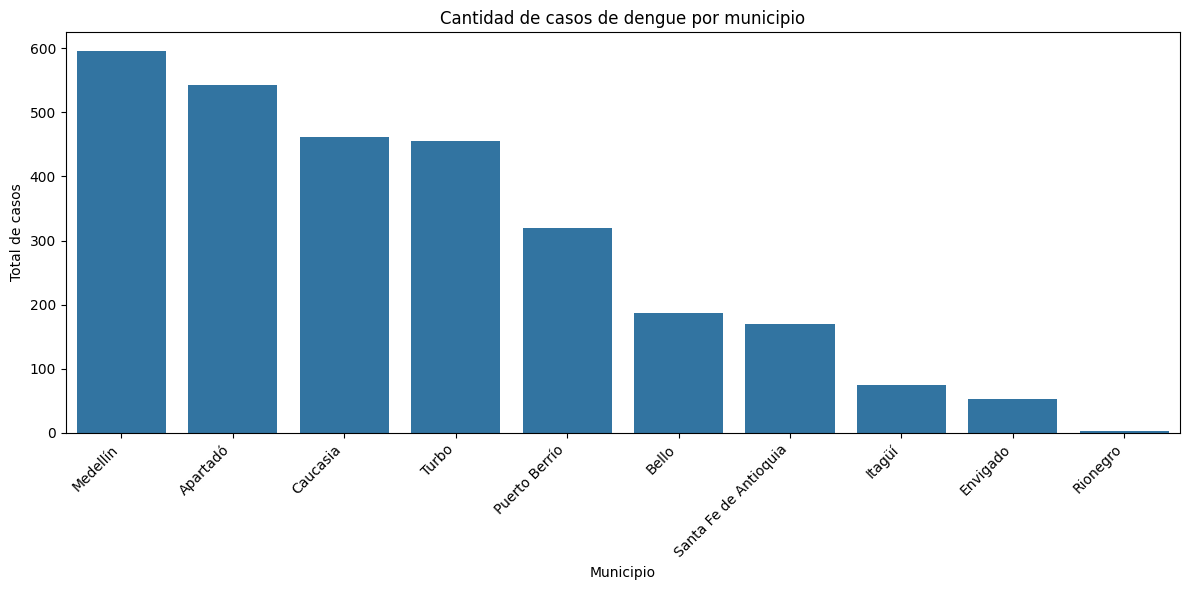

In [91]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=casos_municipio,
    x="municipio",
    y="total_casos"
)

plt.title("Cantidad de casos de dengue por municipio")
plt.xlabel("Municipio")
plt.ylabel("Total de casos")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.savefig(
    DIR_VISUALIZACIONES / 'Cantidad de casos de dengue por municipio.png',
    dpi=300,
    bbox_inches="tight"
)
plt.show()

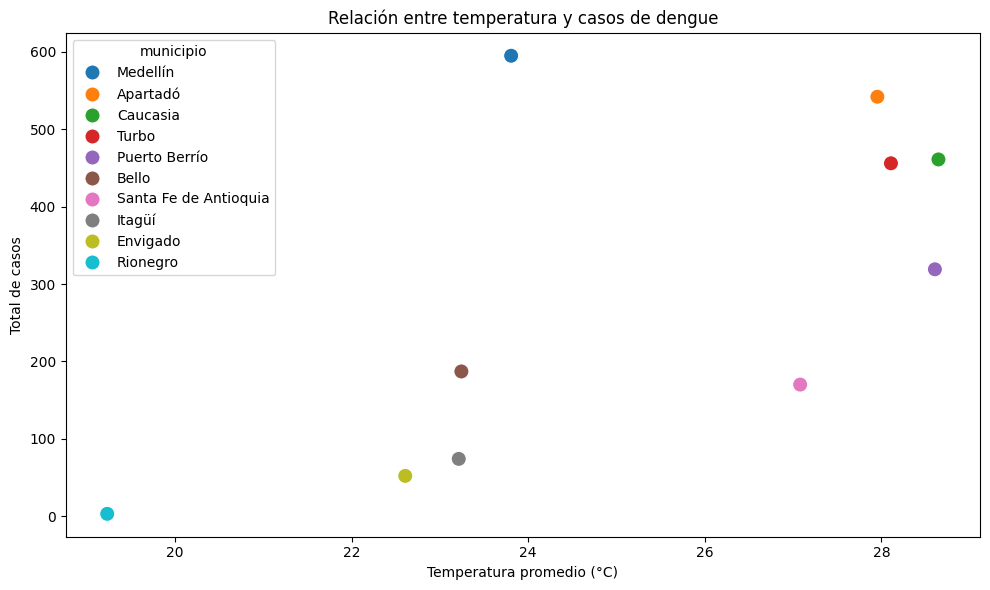

In [92]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=casos_municipio,
    x="temperatura_promedio",
    y="total_casos",
    hue="municipio",
    s=120
)

plt.title("Relación entre temperatura y casos de dengue")
plt.xlabel("Temperatura promedio (°C)")
plt.ylabel("Total de casos")

plt.tight_layout()
plt.savefig(
    DIR_VISUALIZACIONES / 'Relación entre temperatura y casos de dengue.png',
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Conclusión de la pregunta 2: distribución territorial y temperatura

El análisis permitió identificar que Medellín presentó la mayor cantidad de casos de dengue, con 595 notificaciones, seguido de Apartadó con 542 casos.

Por subregiones, Urabá concentró 998 casos y Valle de Aburrá 908, representando conjuntamente aproximadamente el 66,7 % de los registros.

Al comparar la temperatura promedio con el número de casos por municipio, se obtuvo una correlación positiva de 0,657. Este resultado indica una asociación positiva moderadamente fuerte: los municipios con temperaturas promedio más altas tienden a presentar mayores cantidades de casos.

Sin embargo, Medellín demuestra que la temperatura no es el único factor relacionado con la distribución del dengue. También deben considerarse las diferencias poblacionales y ambientales entre municipios.

Desde la perspectiva de salud pública, se recomienda priorizar la vigilancia y las campañas de prevención en Urabá, Valle de Aburrá y municipios como Apartadó, Caucasia y Turbo. Estos resultados describen cantidades de notificaciones y no tasas de incidencia poblacional.

### Pregunta 3. Relación entre los niveles de plaquetas y la gravedad del dengue

In [93]:
plaquetas_clasificacion = (
    df_limpio.groupby("clasificacion")
    .agg(
        cantidad_casos=("id_caso", "count"),
        plaquetas_promedio=("plaquetas_miles", "mean"),
        plaquetas_mediana=("plaquetas_miles", "median"),
        plaquetas_minimas=("plaquetas_miles", "min"),
        plaquetas_maximas=("plaquetas_miles", "max")
    )
    .reset_index()
)

display(plaquetas_clasificacion)

,clasificacion,cantidad_casos,plaquetas_promedio,plaquetas_mediana,plaquetas_minimas,plaquetas_maximas
0,Dengue con signos de alarma,416,80.262019,79.5,24.0,146.0
1,Dengue grave,97,33.103093,33.0,4.0,56.0
2,Dengue sin signos de alarma,2346,144.017903,144.0,29.0,256.0


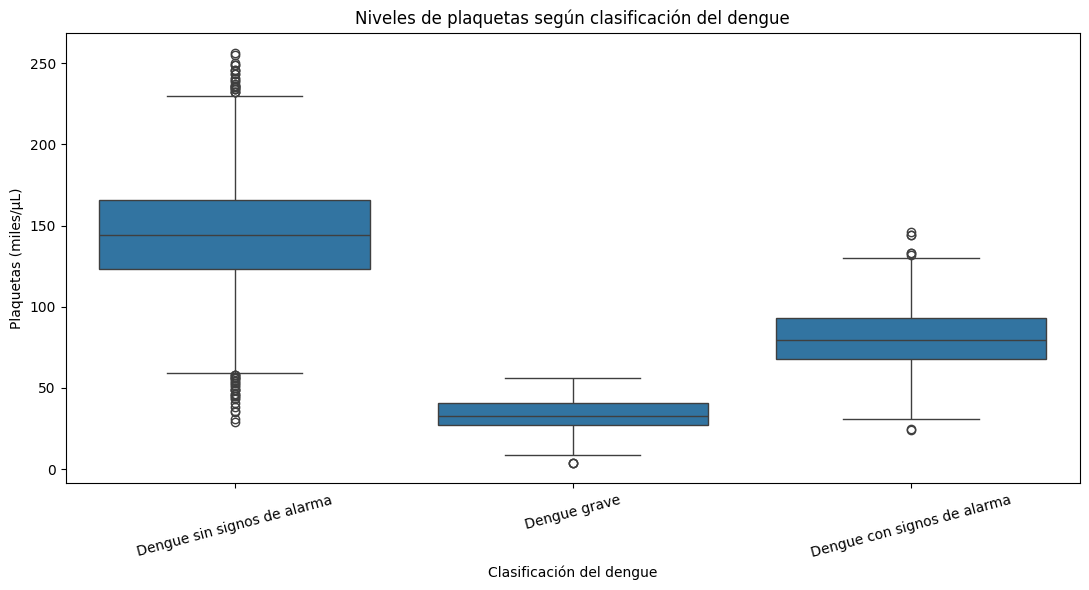

In [94]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df_limpio,
    x="clasificacion",
    y="plaquetas_miles"
)

plt.title("Niveles de plaquetas según clasificación del dengue")
plt.xlabel("Clasificación del dengue")
plt.ylabel("Plaquetas (miles/µL)")
plt.xticks(rotation=15)

plt.tight_layout()

plt.savefig(
    DIR_VISUALIZACIONES / 'Niveles de plaquetas según clasificación del dengue.png',
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Conclusión de la pregunta 3: niveles de plaquetas y clasificación del dengue

El análisis de los 2.859 registros permitió identificar una diferencia importante entre los niveles de plaquetas y la clasificación de los casos de dengue.

Los pacientes clasificados con dengue sin signos de alarma presentaron un promedio de 144,02 miles/µL de plaquetas, mientras que aquellos con signos de alarma registraron un promedio de 80,26 miles/µL. En los casos de dengue grave, el promedio fue considerablemente menor, con 33,10 miles/µL.

La gráfica de cajas permite observar esta diferencia entre las tres clasificaciones, mostrando una tendencia de disminución de los niveles de plaquetas a medida que aumenta la gravedad del dengue.

Estos resultados son consistentes con la importancia de vigilar los niveles de plaquetas en los pacientes con dengue. Sin embargo, las plaquetas no deben utilizarse como único criterio para determinar la gravedad de un paciente.

También debe tenerse en cuenta que algunos valores faltantes fueron imputados mediante la mediana por clasificación, lo cual puede influir en las distribuciones observadas.

Desde la perspectiva de salud pública, estos resultados respaldan la importancia del seguimiento clínico y la identificación oportuna de pacientes que puedan desarrollar complicaciones.

### Pregunta 4. Demora en la consulta y gravedad del dengue

### Objetivo de la pregunta 4

Se busca analizar si existe una relación entre el tiempo transcurrido desde el inicio de los síntomas y la clasificación del dengue. También se comparará la demora en la consulta según la zona de residencia y el régimen de salud.

Este análisis permitirá identificar grupos que podrían presentar mayores dificultades para acceder oportunamente a los servicios médicos. Para ello se utilizarán promedios, medianas y cantidades de registros válidos.

In [95]:
demora_clasificacion = (
    df_limpio.groupby("clasificacion")
    .agg(
        cantidad_casos=("dias_sintomas_a_consulta", "count"),
        demora_promedio=("dias_sintomas_a_consulta", "mean"),
        demora_mediana=("dias_sintomas_a_consulta", "median"),
        demora_maxima=("dias_sintomas_a_consulta", "max")
    )
    .reset_index()
)

display(demora_clasificacion)

,clasificacion,cantidad_casos,demora_promedio,demora_mediana,demora_maxima
0,Dengue con signos de alarma,391,4.762148,4.0,11.0
1,Dengue grave,92,5.163043,5.0,10.0
2,Dengue sin signos de alarma,2220,3.505856,3.0,60.0


In [96]:
demora_zona = (
    df_limpio.groupby("zona")
    .agg(
        cantidad_casos=("dias_sintomas_a_consulta", "count"),
        demora_promedio=("dias_sintomas_a_consulta", "mean"),
        demora_mediana=("dias_sintomas_a_consulta", "median")
    )
    .reset_index()
    .sort_values("demora_promedio", ascending=False)
)

display(demora_zona)

,zona,cantidad_casos,demora_promedio,demora_mediana
0,Rural,761,4.914586,5.0
1,Urbana,1942,3.285273,3.0


In [97]:
demora_regimen = (
    df_limpio.groupby("regimen_salud")
    .agg(
        cantidad_casos=("dias_sintomas_a_consulta", "count"),
        demora_promedio=("dias_sintomas_a_consulta", "mean"),
        demora_mediana=("dias_sintomas_a_consulta", "median")
    )
    .reset_index()
    .sort_values("demora_promedio", ascending=False)
)

display(demora_regimen)

,regimen_salud,cantidad_casos,demora_promedio,demora_mediana
2,No asegurado,125,5.424000,5.0
3,Subsidiado,1292,3.869969,4.0
1,Especial,98,3.459184,3.0
0,Contributivo,1015,3.381281,3.0


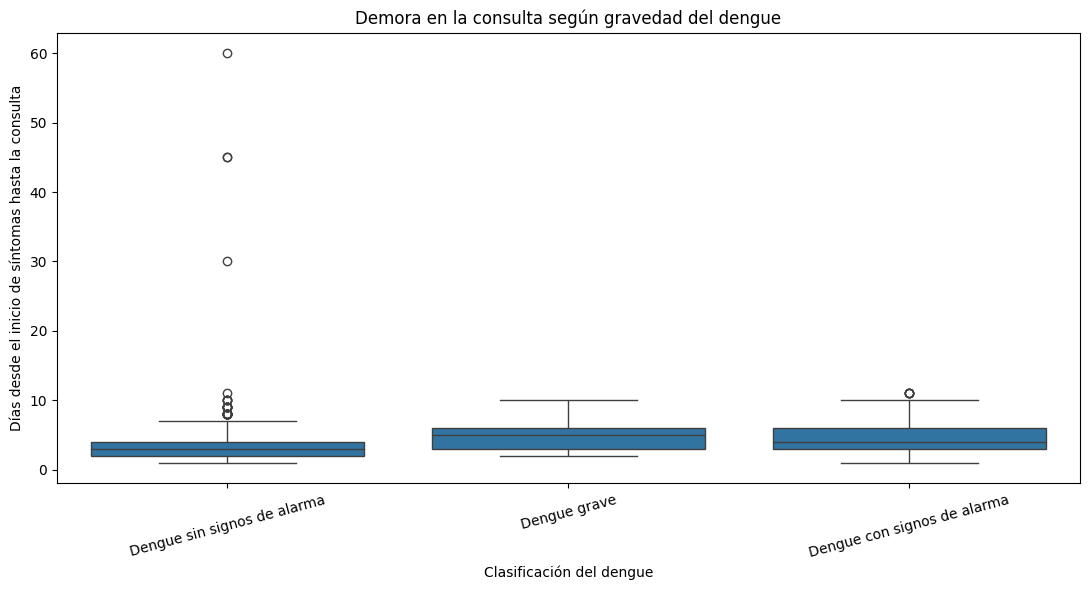

In [98]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df_limpio,
    x="clasificacion",
    y="dias_sintomas_a_consulta"
)

plt.title("Demora en la consulta según gravedad del dengue")
plt.xlabel("Clasificación del dengue")
plt.ylabel("Días desde el inicio de síntomas hasta la consulta")
plt.xticks(rotation=15)

plt.tight_layout()

plt.savefig(
    DIR_VISUALIZACIONES / 'Demora en la consulta según gravedad del dengue.png',
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Conclusión de la pregunta 4: demora en la consulta y gravedad del dengue

Los resultados muestran una asociación entre el tiempo transcurrido desde el inicio de los síntomas hasta la consulta y la clasificación del dengue.

Los pacientes con dengue grave presentaron una demora promedio de 5,16 días, mientras que los pacientes con dengue con signos de alarma registraron 4,76 días y aquellos sin signos de alarma 3,51 días.

Al analizar la zona de residencia, se encontró que los pacientes rurales tardaron en promedio 4,91 días en consultar, frente a 3,29 días de los pacientes urbanos. Esto evidencia una diferencia importante que podría estar relacionada con barreras geográficas o dificultades de acceso a los servicios de salud.

Por régimen de salud, los pacientes no asegurados presentaron la mayor demora promedio, con 5,42 días, seguidos por los afiliados al régimen subsidiado, con 3,87 días.

En conclusión, los resultados sugieren que las demoras en la consulta están asociadas con una mayor gravedad del dengue y que existen diferencias importantes según la zona de residencia y el régimen de salud.

Desde la perspectiva de salud pública, se recomienda fortalecer las estrategias de detección temprana, especialmente en las zonas rurales y en la población no asegurada. Estos resultados son asociaciones descriptivas y no permiten establecer causalidad.

## Conclusiones finales
El análisis de los 2.859 registros de casos de dengue en diez municipios de Antioquia durante 2025 permitió identificar patrones temporales, territoriales y clínicos importantes para la toma de decisiones en salud pública.

En primer lugar, se encontró que los casos de dengue no se distribuyeron uniformemente durante el año. La semana epidemiológica 21 presentó el mayor número de notificaciones, con 119 casos. Además, la correlación entre la precipitación de la semana anterior y los casos actuales fue de 0,451, superior a la correlación entre la lluvia y los casos de la misma semana (0,361). Esto sugiere que las lluvias podrían estar relacionadas con aumentos posteriores de casos.

En segundo lugar, Medellín registró la mayor cantidad de casos, con 595, seguido de Apartadó con 542 y Caucasia con 461. Por subregiones, Urabá concentró 998 casos y Valle de Aburrá 908. También se encontró una correlación positiva de 0,657 entre la temperatura promedio y la cantidad de casos por municipio, lo que sugiere una asociación entre temperaturas más altas y una mayor cantidad de notificaciones.

En tercer lugar, se identificó una relación importante entre los niveles de plaquetas y la clasificación del dengue. Los pacientes con dengue grave presentaron un promedio de 33,10 miles/µL de plaquetas, frente a 80,26 en los casos con signos de alarma y 144,02 en los casos sin signos de alarma. Esto resalta la importancia del seguimiento clínico de los pacientes.

Finalmente, se encontró que los pacientes con dengue grave tardaron en promedio 5,16 días en consultar, mientras que los pacientes sin signos de alarma tardaron 3,51 días. Los habitantes de zonas rurales registraron una demora promedio de 4,91 días y los pacientes no asegurados de 5,42 días. Estos resultados sugieren posibles desigualdades en el acceso oportuno a los servicios de salud.

Como recomendación general, se propone fortalecer las campañas de prevención y control del mosquito en los municipios con mayor número de notificaciones, prestar especial atención a las temporadas posteriores a las lluvias y mejorar el acceso a los servicios de salud en las zonas rurales y para la población no asegurada.

Es importante señalar que el conjunto de datos es sintético y que los resultados muestran asociaciones, no relaciones causales. Además, las cantidades de casos no equivalen a tasas de incidencia, ya que no se dispone de la población total de cada municipio.